# Envision Healthcare: The Sponsor That Held On (and Doubled Down)

This notebook reconstructs Envision Healthcare's trajectory from KKR's 2018
$9.9B take-private through its May 2023 Chapter 11 filing, using only
figures cited in `../docs/sources.md` -- the richest single source being
the 177-page Keglevic first-day declaration.

**A third pattern, different from both companion projects:**

- **Toys "R" Us**: one sponsor holds conventional LBO debt for 12 years
  until it breaks the company.
- **Red Lobster**: the sponsor who engineered the real-estate sale-leaseback
  fully exits in 2020, four years before the actual collapse.
- **Envision Healthcare**: KKR **never exited** -- it still owned 99.67%
  of the equity at the May 2023 filing, and had **bought ~$399M of the
  company's own distressed debt** on top of its original $3.5B equity
  position, doubling down rather than leaving.

This was also Envision's **second** leveraged buyout (CD&R took the
EmCare predecessor private in 2011, too) and the collapse wasn't caused by
one thing -- COVID-19, a specific insurer's payment practices, and two
rounds of debt-exchange "extend and pretend" transactions before the
actual bankruptcy all played a role, and the declaration quantifies each
one separately.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

pre2018 = pd.read_csv("../data/processed/pre_2018_operating_history.csv")
deal = pd.read_csv("../data/processed/deal_2018.csv")
crisis = pd.read_csv("../data/processed/crisis_events.csv")
capstruct = pd.read_csv("../data/processed/capital_structure_silos_2023.csv")
rsa = pd.read_csv("../data/processed/rsa_deleveraging_targets.csv")
outcome = pd.read_csv("../data/processed/bankruptcy_outcome_2023.csv")
pre2018

,period,net_revenue_musd,operating_income_musd,operating_margin_pct,source,notes
0,FY2015,NaN,NaN,24.1,FY2017 10-K common-size table,Pre-AmSurg-merger entity -- not directly compa...
1,FY2016,NaN,NaN,10.6,FY2017 10-K common-size table,Year of the Envision Healthcare Holdings / AmS...
2,FY2017,7819.3,189.2,2.4,FY2017 10-K selected financial data,First full year as the combined company -- the...


## 1. A margin already collapsing before KKR arrived

Envision's own 10-K shows operating margin falling from 24.1% (FY2015) to
just 2.4% (FY2017) -- though this spans the 2016 "merger of equals" with
AmSurg, so part of the shift reflects a different, larger combined entity,
not pure like-for-like decay. Either way: KKR paid ~$9.9B for a company
whose own filings showed a thin and shrinking margin.

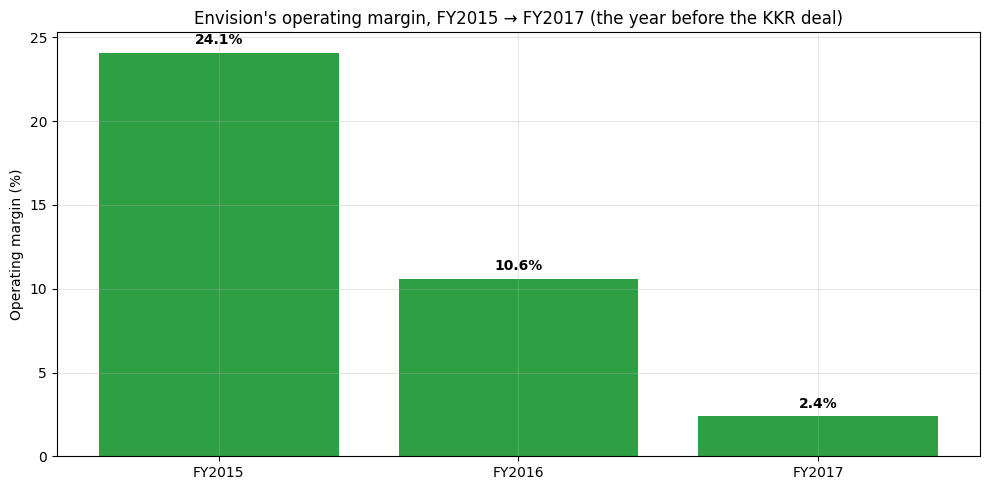

period  net_revenue_musd  operating_income_musd  operating_margin_pct                              source                                                                                                   notes
FY2015               NaN                    NaN                  24.1       FY2017 10-K common-size table           Pre-AmSurg-merger entity -- not directly comparable to FY2017's combined-company revenue base
FY2016               NaN                    NaN                  10.6       FY2017 10-K common-size table Year of the Envision Healthcare Holdings / AmSurg 'merger of equals' (Dec 2016) -- mixed-perimeter year
FY2017            7819.3                  189.2                   2.4 FY2017 10-K selected financial data         First full year as the combined company -- the entry-year financial picture KKR was buying into


In [2]:
fig, ax = plt.subplots()
x = range(len(pre2018))
ax.bar(x, pre2018["operating_margin_pct"], color="#2ea043")
ax.set_xticks(list(x))
ax.set_xticklabels(pre2018["period"])
ax.set_ylabel("Operating margin (%)")
ax.set_title("Envision's operating margin, FY2015 → FY2017 (the year before the KKR deal)")
for i, v in enumerate(pre2018["operating_margin_pct"]):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("../assets/chart_margin_decline.png", dpi=140)
plt.show()
print(pre2018.to_string(index=False))

## 2. The 2018 deal: equity vs. debt

$3.5B of KKR equity against up to $8.05B of debt financing commitments --
a more conventional LBO funding mix than Red Lobster's real-estate-funded
structure, but still roughly 2.3x debt-to-equity on the commitment letters
alone.

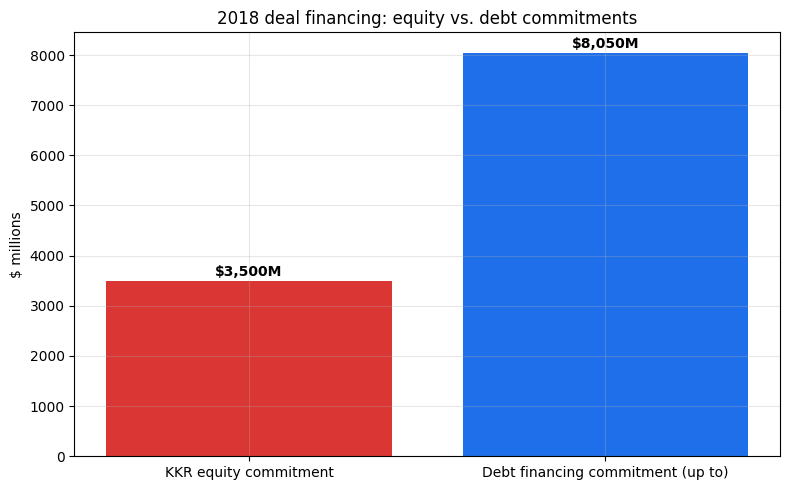

                                      item  value_musd                         source                                                                                                                                           notes
                   Total transaction value      9900.0        Press / widely reported                                                                                                  Includes assumption/repayment of existing debt
            Per-share merger consideration        46.0                        DEFM14A                                                                                       USD per share, cash, 32% premium to VWAP since Nov 1 2017
                     KKR equity commitment      3500.0                        DEFM14A                                                                                             'An aggregate amount in cash equal to $3.5 billion'
         Debt financing commitment (up to)      8050.0                        DE

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
items = deal[deal["item"].isin(["KKR equity commitment", "Debt financing commitment (up to)"])]
ax.bar(items["item"], items["value_musd"], color=["#da3633", "#1f6feb"])
ax.set_ylabel("$ millions")
ax.set_title("2018 deal financing: equity vs. debt commitments")
for i, v in enumerate(items["value_musd"]):
    ax.text(i, v + 100, f"${v:,.0f}M", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("../assets/chart_2018_financing.png", dpi=140)
plt.show()
print(deal.to_string(index=False))

## 3. What actually broke the company: three forces, quantified separately

The first-day declaration is unusually precise about attributing the
damage. None of these alone would likely have been fatal -- together,
against a company that started with a thin margin, they were.

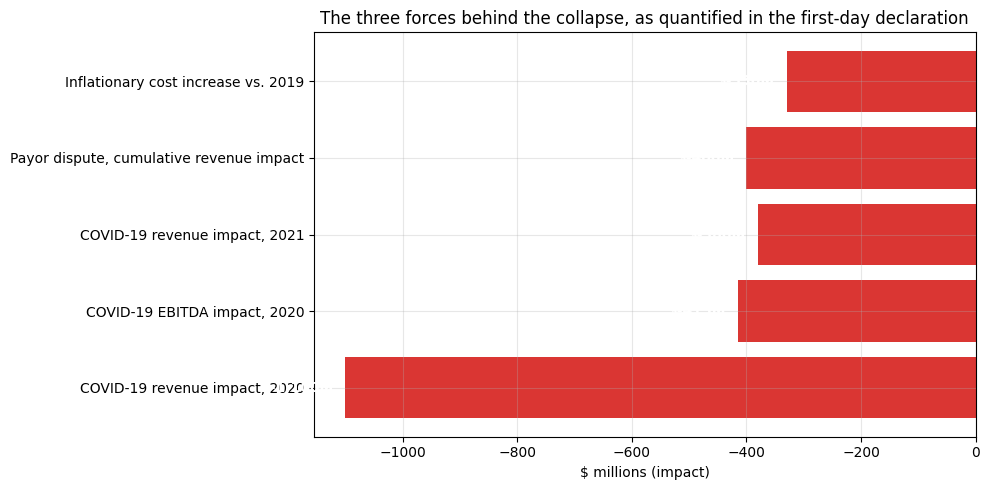

In [4]:
forces = pd.DataFrame([
    {"force": "COVID-19 revenue impact, 2020", "musd": -1100},
    {"force": "COVID-19 EBITDA impact, 2020", "musd": -415},
    {"force": "COVID-19 revenue impact, 2021", "musd": -380},
    {"force": "Payor dispute, cumulative revenue impact", "musd": -400},
    {"force": "Inflationary cost increase vs. 2019", "musd": -330},
])
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#da3633"] * len(forces)
ax.barh(forces["force"], forces["musd"], color=colors)
ax.set_xlabel("$ millions (impact)")
ax.set_title("The three forces behind the collapse, as quantified in the first-day declaration")
for i, v in enumerate(forces["musd"]):
    ax.text(v - 20, i, f"${v:,.0f}M", va="center", ha="right", color="white", fontweight="bold")
plt.tight_layout()
plt.savefig("../assets/chart_crisis_forces.png", dpi=140)
plt.show()

## 4. "Extend and pretend": two rounds of debt exchanges before the real thing

Before filing Chapter 11, Envision (specifically the AMSURG silo and then
the broader capital structure) ran two debt-exchange transactions designed
to buy time by letting creditors accept less than face value today in
exchange for extended maturities. Both captured real accounting
"discount" -- and neither fixed the underlying problem.

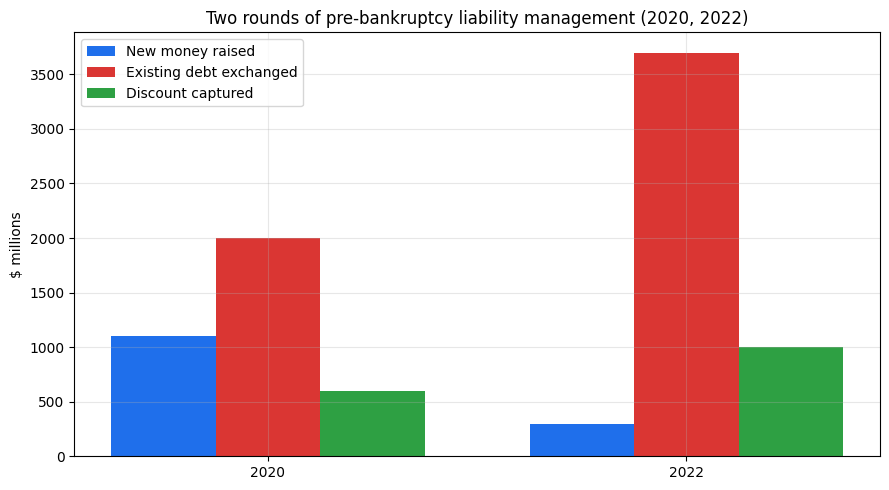

Combined across both rounds: $ 1600 million of discount captured --
i.e., creditors agreed to accept that much less than face value, on paper reducing the debt load --
but $7.7B of funded debt still remained outstanding at the actual May 2023 filing.


In [5]:
lm = pd.DataFrame([
    {"year": "2020", "new_money_raised": 1100, "existing_debt_exchanged": 2000, "discount_captured": 600},
    {"year": "2022", "new_money_raised": 300, "existing_debt_exchanged": 3700, "discount_captured": 1000},
])
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(lm))
width = 0.25
ax.bar([i - width for i in x], lm["new_money_raised"], width, label="New money raised", color="#1f6feb")
ax.bar([i for i in x], lm["existing_debt_exchanged"], width, label="Existing debt exchanged", color="#da3633")
ax.bar([i + width for i in x], lm["discount_captured"], width, label="Discount captured", color="#2ea043")
ax.set_xticks(list(x))
ax.set_xticklabels(lm["year"])
ax.set_ylabel("$ millions")
ax.set_title("Two rounds of pre-bankruptcy liability management (2020, 2022)")
ax.legend()
plt.tight_layout()
plt.savefig("../assets/chart_liability_management.png", dpi=140)
plt.show()
print("Combined across both rounds: $", lm['discount_captured'].sum(), "million of discount captured --")
print("i.e., creditors agreed to accept that much less than face value, on paper reducing the debt load --")
print("but $7.7B of funded debt still remained outstanding at the actual May 2023 filing.")

## 5. The dual-silo capital structure at filing

$7.7 billion of funded debt, split across two largely separate financing
structures tied to Envision's two operating segments -- a structural
feature neither of this project's companion case studies had.

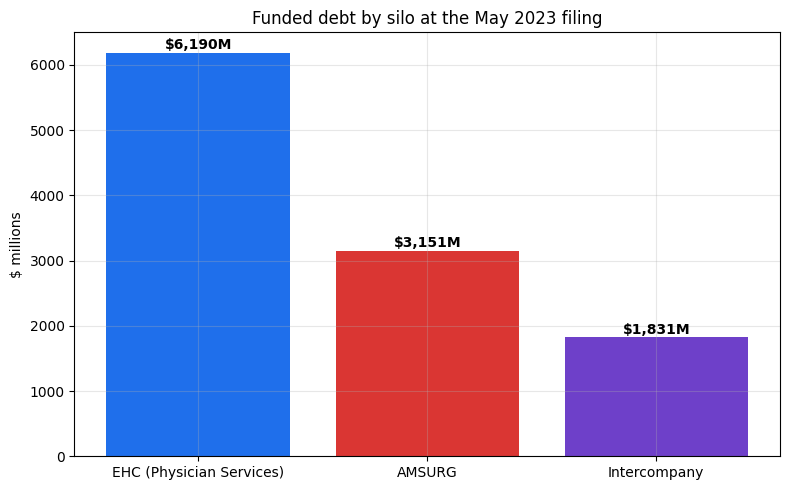

                    silo                                 facility  amount_musd                           detail                source
EHC (Physician Services)                Revolving Credit Facility          300                        committed First-day declaration
EHC (Physician Services)        Term Loan Facility (all tranches)         5450 'first out' through 'fourth out' First-day declaration
EHC (Physician Services)                       ABL Facility drawn          440    of up to $550M-$1.0B capacity First-day declaration
                  AMSURG                Revolving Credit Facility          300                        committed First-day declaration
                  AMSURG First Lien Term Loan (incl. incremental)         1358                              NaN First-day declaration
                  AMSURG        Second Lien Term Loan outstanding         1493                after repurchases First-day declaration
            Intercompany             Short-term loans outstand

In [6]:
silo_totals = capstruct.groupby("silo")["amount_musd"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(silo_totals.index, silo_totals.values, color=["#1f6feb", "#da3633", "#6e40c9"])
ax.set_ylabel("$ millions")
ax.set_title("Funded debt by silo at the May 2023 filing")
for i, v in enumerate(silo_totals.values):
    ax.text(i, v + 50, f"${v:,.0f}M", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("../assets/chart_dual_silo.png", dpi=140)
plt.show()
print(capstruct.to_string(index=False))

## 6. The sponsor who stayed

Unlike Golden Gate Capital at Red Lobster, KKR was still the controlling
equity holder at the moment of filing -- and had been buying the
company's own distressed debt on top of its equity position.

In [7]:
kkr = crisis[crisis["event"].str.contains("KKR")]
print(kkr.to_string(index=False))
print()
print("KKR's original equity commitment (2018): $3,500M")
print("KKR's distressed debt position at filing (2023): ~$399M (146M Term Loans + 253M Senior Notes)")
print()
print(outcome.to_string(index=False))

                                            event  value_musd     period                                              source
  KKR's purchased distressed Term Loans at filing         146 2023-05-15 First-day declaration ¶27, 'second out'/'third out'
KKR's purchased distressed Senior Notes at filing         253 2023-05-15                           First-day declaration ¶27

KKR's original equity commitment (2018): $3,500M
KKR's distressed debt position at filing (2023): ~$399M (146M Term Loans + 253M Senior Notes)

                              item                                                                                                                                                                                                                                                 value                                        source
                       Filing date                                                                                                                       

## 7. Conclusions

1. **KKR bought a company whose own numbers already showed trouble.**
   Operating margin had fallen to 2.4% by the last full pre-deal fiscal
   year -- this wasn't a stable asset destabilized by debt; it was a
   margin-thin business made more fragile by debt.
2. **The collapse had multiple, separately quantifiable causes.** COVID-19
   (~$1.9B combined revenue impact across 2020-2021), a specific payor's
   adverse practices (~$400M), and inflation (~$330M) all hit a company
   that started with little room to absorb any one of them, let alone all
   three.
3. **"Extend and pretend" bought about three years, not a solution.** Two
   rounds of debt exchanges captured over $1.6B of paper discount combined
   -- real financial engineering, not nothing -- but $7.7B of debt still
   remained at the actual filing. Delaying a restructuring is not the same
   as avoiding one.
4. **This sponsor did not leave.** KKR held its equity through the filing
   and bought more of the company's distressed debt along the way -- the
   opposite of Red Lobster's pattern, closer to (and in some ways more
   committed than) Toys "R" Us's.
5. **The resolution was a lender-to-owner conversion, not a sale to a new
   sponsor** -- the same basic mechanism as Red Lobster's outcome (Fortress
   credit-bidding its own debt), here executed by PIMCO, Blackstone, and
   Brigade Capital converting debt into equity across both resulting
   companies.